In [1]:
# ---- LOAD THE WEEK 6 COMPARISON DATA ----
import os
import json
import glob

BASE = os.path.expanduser('~/easyf1')
results_dir = os.path.join(BASE, 'results')

# Find the full-15 comparison file
files = sorted(glob.glob(os.path.join(results_dir, 'comparison_full15_*.json')))
# Exclude the _meta files
data_files = [f for f in files if not f.endswith('_meta.json')]

print("Found comparison files:")
for f in data_files:
    print(f"  {os.path.basename(f)}")

# Load the most recent one
latest = data_files[-1]
with open(latest, 'r') as f:
    scenarios_data = json.load(f)

print(f"\nLoaded: {os.path.basename(latest)}")
print(f"Scenarios: {len(scenarios_data)}")
print(f"\nEach scenario has these keys: {list(scenarios_data[0].keys())}")
print(f"\nFirst scenario preview:")
print(f"  Scenario: {scenarios_data[0]['scenario'][:100]}...")
print(f"  Context chunks: {len(scenarios_data[0]['context'])}")
print(f"  Has Gemini answer: {'gemini' in scenarios_data[0]}")
print(f"  Has Nemotron answer: {'nemotron' in scenarios_data[0]}")

Found comparison files:
  comparison_full15_20260907_184605.json

Loaded: comparison_full15_20260907_184605.json
Scenarios: 15

Each scenario has these keys: ['scenario', 'context', 'gemini', 'nemotron', 'scenario_num']

First scenario preview:
  Scenario: It's lap 32 of 52 at the 2023 British Grand Prix (Silverstone). Lewis Hamilton is P4 on 30-lap-old h...
  Context chunks: 6
  Has Gemini answer: True
  Has Nemotron answer: True


In [2]:

# 5 additional scenarios in addition to previous 15


scenarios_batch3 = [
    # 16. High-degradation street circuit, undercut vs track position
    "It's lap 18 of 50 at the 2022 Azerbaijan Grand Prix (Baku). A driver is "
    "P5 on 16-lap-old soft tyres, struggling with degradation on the long "
    "straights. The car behind is closing. Should they pit now for hards, or "
    "risk staying out to hold track position?",

    # 17. Late-race two-stopper catching a one-stopper (strategy divergence)
    "It's lap 40 of 53 at the 2023 Spanish Grand Prix. A driver on a two-stop "
    "strategy is P6 on fresh softs, 8 seconds behind a one-stopper in P5 who is "
    "on 25-lap-old hards. Is there enough time and tyre advantage to catch and "
    "pass before the finish?",

    # 18. Weather gamble — dry to wet (opposite of the earlier wet scenario)
    "It's lap 20 of 44 at a race where rain has just started falling lightly. "
    "A driver is P3 on slick tyres. Some rivals are staying out. Should they "
    "pit for intermediates now or wait to see if the rain intensifies?",

    # 19. Safety car right before a planned stop (timing windfall)
    "It's lap 26 of 58 at the 2023 Qatar Grand Prix. A driver in P4 was "
    "planning to pit in 2-3 laps anyway when a Safety Car is suddenly deployed. "
    "Should they dive into the pits immediately to take the cheap stop?",

    # 20. Long opening stint decision at a low-deg circuit
    "It's lap 15 of 44 at the 2021 Italian Grand Prix (Monza), a low-degradation "
    "circuit. A driver is P4 on medium tyres that still feel strong. Should they "
    "extend this stint well past the normal window to gain track position through "
    "strategic offset?",
]

print(f"Batch 3: {len(scenarios_batch3)} new scenarios (16-20)")
for i, s in enumerate(scenarios_batch3, 16):
    print(f"\n{i}. {s[:75]}...")

Batch 3: 5 new scenarios (16-20)

16. It's lap 18 of 50 at the 2022 Azerbaijan Grand Prix (Baku). A driver is P5 ...

17. It's lap 40 of 53 at the 2023 Spanish Grand Prix. A driver on a two-stop st...

18. It's lap 20 of 44 at a race where rain has just started falling lightly. A ...

19. It's lap 26 of 58 at the 2023 Qatar Grand Prix. A driver in P4 was planning...

20. It's lap 15 of 44 at the 2021 Italian Grand Prix (Monza), a low-degradation...


In [3]:

# Import engine functions + run batch 3

import sys
import os

BASE = os.path.expanduser('~/easyf1')

# Add the app folder to the path so we can import engine.py
sys.path.insert(0, os.path.join(BASE, 'app'))
import engine

print("Engine imported ✅")

# Run the 5 new scenarios through both models
import time

batch3_results = []
for idx, scenario in enumerate(scenarios_batch3):
    scenario_num = idx + 16
    print(f"\n{'#'*55}")
    print(f"# SCENARIO {scenario_num} of 20")
    print(f"{'#'*55}")
    print(f"{scenario[:90]}...")
    
    # engine.compare returns dict with scenario, context, gemini, nemotron
    result = engine.compare(scenario)
    result['scenario_num'] = scenario_num
    batch3_results.append(result)
    
    # Quick preview
    print(f"\n  Gemini: {result['gemini'][:60]}...")
    print(f"  Nemotron: {result['nemotron'][:60]}...")
    
    if idx < len(scenarios_batch3) - 1:
        print("\n[pausing 6s...]")
        time.sleep(6)

print(f"\n\n{'='*55}")
print(f"BATCH 3 COMPLETE: {len(batch3_results)} scenarios ✅")
print(f"{'='*55}")

Engine imported ✅

#######################################################
# SCENARIO 16 of 20
#######################################################
It's lap 18 of 50 at the 2022 Azerbaijan Grand Prix (Baku). A driver is P5 on 16-lap-old s...


Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.



  Gemini: VERDICT: Pit now for hard tyres to mitigate degradation and ...
  Nemotron: VERDICT: Pit now for hard tyres to avoid losing track positi...

[pausing 6s...]

#######################################################
# SCENARIO 17 of 20
#######################################################
It's lap 40 of 53 at the 2023 Spanish Grand Prix. A driver on a two-stop strategy is P6 on...

  Gemini: VERDICT: Attempt the overtake, as the fresh soft tyres offer...
  Nemotron: VERDICT: Yes, push to catch and pass P5 before the finish.
C...

[pausing 6s...]

#######################################################
# SCENARIO 18 of 20
#######################################################
It's lap 20 of 44 at a race where rain has just started falling lightly. A driver is P3 on...

  Gemini: VERDICT: Pit for intermediate tyres now.
CONFIDENCE: Medium
...
  Nemotron: VERDICT: Pit for intermediates now rather than waiting to se...

[pausing 6s...]

#########################################

In [4]:

# Merging all 20 scenarios + saving as a evaluation set
import json
import pickle
from datetime import datetime

# scenarios_data holds the original 15 (loaded earlier)
# batch3_results holds the new 5
full_20 = scenarios_data + batch3_results
full_20.sort(key=lambda x: x['scenario_num'])

# Verify we have a clean 1-20
nums = [r['scenario_num'] for r in full_20]
print(f"Total scenarios: {len(full_20)}")
print(f"Scenario numbers: {nums}")

# Save as the official evaluation dataset
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
eval_dir = os.path.join(BASE, 'results')

json_path = os.path.join(eval_dir, f'eval_dataset_20_{timestamp}.json')
with open(json_path, 'w') as f:
    json.dump(full_20, f, indent=2)

pkl_path = os.path.join(eval_dir, f'eval_dataset_20_{timestamp}.pkl')
with open(pkl_path, 'wb') as f:
    pickle.dump(full_20, f)

print(f"\nSaved evaluation dataset ✅")
print(f"  JSON:   {os.path.basename(json_path)}")
print(f"  Pickle: {os.path.basename(pkl_path)}")

# Quick sanity check — both models answered every scenario?
missing = [r['scenario_num'] for r in full_20 
           if not r.get('gemini') or not r.get('nemotron')]
if missing:
    print(f"\n⚠️ Scenarios missing an answer: {missing}")
else:
    print(f"\n✅ All 20 scenarios have both models' answers")

Total scenarios: 20
Scenario numbers: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]

Saved evaluation dataset ✅
  JSON:   eval_dataset_20_20260912_150505.json
  Pickle: eval_dataset_20_20260912_150505.pkl

✅ All 20 scenarios have both models' answers


In [5]:

# Ground-truth key for all 20 test scenarios
import os, json, pickle
from datetime import datetime

BASE = os.path.expanduser('~/easyf1')

ground_truth = [
    {"scenario_num": 1, "expected_verdict": "PIT", "confidence": "High",
     "historical_basis": "2023 British GP: Hamilton pitted lap 33 under this SC (33-lap mediums to softs), finished P3. Multiple drivers pitted in window.",
     "principle_basis": "SC cuts pit-loss ~60-70% (to ~10-12s). 30-lap hards near end of life with 20 laps left.",
     "key_factors": ["SC reduces pit loss", "tyre age vs remaining laps", "free-stop opportunity", "historical precedent"]},

    {"scenario_num": 2, "expected_verdict": "YES (undercut)", "confidence": "Medium",
     "historical_basis": "Hungaroring is notorious for undercut power; overtaking very hard, undercut is primary passing method.",
     "principle_basis": "2s gap within undercut range; fresh vs 20-lap mediums gives pace delta to overcome pit loss. Risk: P4 covers next lap.",
     "key_factors": ["Hungary hard to overtake", "undercut pace delta", "2s within range", "risk of being covered"]},

    {"scenario_num": 3, "expected_verdict": "AMBIGUOUS (lean one-stop)", "confidence": "Low",
     "historical_basis": "2021 French GP decided by strategy — Verstappen's two-stop caught Hamilton's one-stop late. Both viable; two-stop won.",
     "principle_basis": "Hard tyres at Paul Ricard can go long (favours one-stop), but deg high enough that two-stop paid off. Genuine coin-flip; ideal answer acknowledges trade-off.",
     "key_factors": ["hard tyre longevity", "degradation rate", "2021 one-vs-two battle", "track position vs fresh rubber"]},

    {"scenario_num": 4, "expected_verdict": "STAY OUT (defend)", "confidence": "Medium-High",
     "historical_basis": "Only 8 laps left; field data shows no green-flag stops this late unless tyres gone.",
     "principle_basis": "~22s pit loss unrecoverable in 8 laps (needs ~2.75s/lap). Track position wins. Pit only if tyres finished.",
     "key_factors": ["pit-loss vs laps remaining", "break-even calculation", "track position priority", "tyre cliff risk"]},

    {"scenario_num": 5, "expected_verdict": "SOON not yet (switch as crossover nears)", "confidence": "Medium",
     "historical_basis": "Inter-to-slick crossovers timing-critical; too early loses grip, too late loses time. Track-evolution dependent.",
     "principle_basis": "Crossover = when slick lap time beats inter. 'Getting faster' signals window opening, may not be open yet. Best answer stresses timing, not blind immediate switch.",
     "key_factors": ["crossover timing", "risk of switching too early", "track drying rate", "monitoring pace delta"]},

    {"scenario_num": 6, "expected_verdict": "STAY OUT (don't pit)", "confidence": "Medium-High",
     "historical_basis": "Pitting lap 8 commits leader to ~36-lap final stint — far longer than typical medium stint in data.",
     "principle_basis": "Cheap SC stop only worth it if resulting stint survivable. Lap 8/44 too early; surrenders later-SC option. Free-stop benefit < stint-length risk.",
     "key_factors": ["resulting stint length vs tyre life", "too early to commit", "losing later-SC option", "leader has most to lose"]},

    {"scenario_num": 7, "expected_verdict": "PIT (cover)", "confidence": "Medium-High",
     "historical_basis": "Rival pitting onto fresh tyres; staying out on aging tyres risks undercut. Covering is standard defensive response.",
     "principle_basis": "Overcut only works low-deg + cool/slow warm-up. Red Bull Ring not strong overcut track; aging mediums vs fresh = classic undercut-vulnerable. Cover unless reason to gamble.",
     "key_factors": ["undercut threat", "overcut conditions absent", "aging tyres vulnerable", "defensive cover standard"]},

    {"scenario_num": 8, "expected_verdict": "EXTEND (stay out)", "confidence": "High",
     "historical_basis": "Monaco = ultimate track-position circuit; overtaking near-impossible. Hard tyres routinely go 30+ laps.",
     "principle_basis": "Where you can't overtake, giving up track position for fresh rubber rarely worth it. Tyres 'decent' at 22 laps — extend clearly correct. Only a problem forces a stop.",
     "key_factors": ["Monaco track position paramount", "hard tyre longevity", "overtaking near-impossible", "tyres still good"]},

    {"scenario_num": 9, "expected_verdict": "YES (double-stack)", "confidence": "Medium",
     "historical_basis": "Double-stacking under SC is common team tactic; lead car served first. Lap 25 aligns with reasonable Barcelona first-stop window.",
     "principle_basis": "SC makes stop cheap for both; double-stack captures value. Risk: second car (P6) loses time if first stop slow. EV favours it when both need tyres.",
     "key_factors": ["SC cheap stop for both", "lead car first", "second-car delay risk", "both need tyres"]},

    {"scenario_num": 10, "expected_verdict": "SETTLE for P4", "confidence": "Medium-High",
     "historical_basis": "Hungary among hardest to overtake. Closing 12s in 9 laps needs ~1.3s/lap in dirty air — rarely delivered by 15-lap advantage.",
     "principle_basis": "15-lap fresh advantage typically <1s/lap warmed. 1.3s/lap for 9 laps at no-overtaking circuit unrealistic. Push for error but P4 honest ceiling.",
     "key_factors": ["12s in 9 laps = ~1.3s/lap", "Hungary hard to overtake", "realistic pace delta", "low success probability"]},

    {"scenario_num": 11, "expected_verdict": "STAY OUT (don't ultra-early stop)", "confidence": "Medium",
     "historical_basis": "Ultra-early lap-6 stop forces long middle stint, drops into traffic off-sequence. Graining often eases as surface cleans.",
     "principle_basis": "Graining frequently transient — tyres recover. Reacting on lap 6 risks over-reaction; commits ~46 laps remaining for little gain. Nurse a few laps, pit normal window.",
     "key_factors": ["graining can be transient", "ultra-early forces long stint", "off-sequence into traffic", "over-reaction risk"]},

    {"scenario_num": 12, "expected_verdict": "AMBIGUOUS (lean stay out)", "confidence": "Low",
     "historical_basis": "Late SC with comfortable margin is genuine fork. Stay out protects podium; pit for softs offers attack but risks position. Teams split.",
     "principle_basis": "6 laps left; fresh-soft restart pace strong but track position known and podium comfortable. Safe play protects P3; gamble chases nothing unless cars ahead vulnerable. Conditional.",
     "key_factors": ["comfortable position = protect", "soft restart pace", "what cars behind do", "risk vs certain podium"]},

    {"scenario_num": 13, "expected_verdict": "PIT (fresh tyres)", "confidence": "Medium-High",
     "historical_basis": "Monza 2023: mediums to hards ~laps 19-21; 30-lap medium stint past window. Easy overtaking makes pit-lane position recoverable.",
     "principle_basis": "Monza easiest to overtake (straights, DRS, slipstream) — inverts track-position logic. Pitting low-risk, positions regained on track. 30-lap mediums past best.",
     "key_factors": ["Monza easy overtaking inverts logic", "medium stint past window", "fresh-tyre pace", "position recoverable"]},

    {"scenario_num": 14, "expected_verdict": "PIT (cover undercut)", "confidence": "Medium-High",
     "historical_basis": "P2 within undercut range about to pit; leader must respond or be jumped. Pit first/same lap is standard defence. Paul Ricard deg makes undercut real.",
     "principle_basis": "Undercut potent when chaser close + tyres worn. Leader hesitating one lap loses position. Cover by pitting first. Stay out only if clearly more durable compound.",
     "key_factors": ["undercut threat in range", "pit first to defend", "one lap hesitation loses position", "deg makes undercut real"]},

    {"scenario_num": 15, "expected_verdict": "STAY OUT / one-stop (minimise stops)", "confidence": "Medium-High",
     "historical_basis": "Monaco overtaking near-impossible; stop dropping into traffic very costly. Drivers hold position by extending, minimising stops.",
     "principle_basis": "Monaco track position dominates. Clean air + no SC = pitting risks emerging in traffic with no way past. One-stop/long stint protects position. Stop only if tyres finished.",
     "key_factors": ["Monaco track position paramount", "clean air valuable", "no SC = full pit loss", "risk emerging in traffic"]},

    {"scenario_num": 16, "expected_verdict": "PIT (for hards)", "confidence": "Medium-High",
     "historical_basis": "Baku long straights punish degraded tyres; worn softs defenceless into DRS zones. 16-lap softs near end of window.",
     "principle_basis": "Power circuit: degraded softs especially vulnerable (slipstream + DRS). Hards restore pace. Baku long pit lane costlier, but holding on dying softs while caught is worse.",
     "key_factors": ["Baku straights punish worn tyres", "DRS vulnerability", "soft near end of life", "long pit lane caveat"]},

    {"scenario_num": 17, "expected_verdict": "YES (realistic catch)", "confidence": "Medium",
     "historical_basis": "Fresh-soft vs 25-lap-hard delta at Barcelona can exceed 1s/lap. 8s over 13 laps needs ~0.6s/lap — achievable. Barcelona allows some overtaking (DRS + main straight).",
     "principle_basis": "Two-stop pays only if fresher tyres close gap in time. ~0.6s/lap within fresh-soft-vs-old-hard delta. Realistic not guaranteed — traffic + one-stopper managing are variables.",
     "key_factors": ["8s over 13 laps = ~0.6s/lap", "fresh soft vs old hard delta", "Barcelona allows overtaking", "two-stop payoff condition"]},

    {"scenario_num": 18, "expected_verdict": "AMBIGUOUS (lean wait/assess)", "confidence": "Low-Medium",
     "historical_basis": "Crossover calls in changing conditions highest-variance in F1. Light rain that stops makes inters wrong call; pouring makes waiting wrong.",
     "principle_basis": "Inter/slick crossover depends how wet it gets. 'Light rain just started' uncertain — gather a lap of info vs react instantly. From P3, protect position argues against panic stop. Conditions-dependent.",
     "key_factors": ["crossover high-variance", "light vs intensifying rain", "one lap of information", "P3 to protect", "conditions-dependent"]},

    {"scenario_num": 19, "expected_verdict": "PIT (cheap SC stop)", "confidence": "High",
     "historical_basis": "Clearest call in set. 2025 Qatar GP: Verstappen pitted lap 7 under SC, saved ~10s vs green stop; Pirelli noted SC conditioned all strategy.",
     "principle_basis": "SC halves pit loss (~10-12s). Going to pit within 2-3 laps regardless — take near-free ~10s now. Stint-length change trivial. Almost no downside.",
     "key_factors": ["already planning to pit", "SC halves pit loss", "~10s near-free", "trivial stint impact", "textbook cheap stop"]},

    {"scenario_num": 20, "expected_verdict": "AMBIGUOUS (measured extension, not extreme)", "confidence": "Low-Medium",
     "historical_basis": "Monza low-deg: longer stints viable, strategic offset real. But extending too far costs pace, invites undercut.",
     "principle_basis": "Low-deg favours overcut/extension; clean-air offset gains position. But 'well past normal window' overstates — benefit has limits. Good answer endorses measured extension, not unlimited.",
     "key_factors": ["Monza low-deg favours extension", "strategic offset real", "limits exist", "undercut risk if too far"]},
]

# Verify and save
print(f"Ground-truth records: {len(ground_truth)}")
print(f"Scenario numbers: {[g['scenario_num'] for g in ground_truth]}")

# Confidence distribution (useful for the dissertation)
from collections import Counter
conf_dist = Counter(g['confidence'] for g in ground_truth)
print(f"\nConfidence distribution:")
for conf, count in conf_dist.items():
    print(f"  {conf}: {count}")

# Save
ts = datetime.now().strftime("%Y%m%d_%H%M%S")
gt_path = os.path.join(BASE, 'results', f'ground_truth_20_{ts}.json')
with open(gt_path, 'w') as f:
    json.dump(ground_truth, f, indent=2)
print(f"\nSaved ✅ {os.path.basename(gt_path)}")

Ground-truth records: 20
Scenario numbers: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]

Confidence distribution:
  High: 3
  Medium: 5
  Low: 2
  Medium-High: 8
  Low-Medium: 2

Saved ✅ ground_truth_20_20260912_154144.json


In [6]:
# ---- PICK A JUDGE: check strong free models are live ----
import os, requests, json
from dotenv import load_dotenv

BASE = os.path.expanduser('~/easyf1')
load_dotenv(dotenv_path=os.path.join(BASE, '.env'))
OPENROUTER_KEY = os.getenv("OPENROUTER_API_KEY")

# Candidate judges — capable, neutral (NOT Nemotron, NOT Gemini)
candidates = [
    "z-ai/glm-5.2:free",
    "minimax/minimax-m3:free",
    "nvidia/nemotron-3-super-120b-a12b:free",  # different from your contestant (Ultra)
]

def quick_test(model):
    resp = requests.post(
        "https://openrouter.ai/api/v1/chat/completions",
        headers={"Authorization": f"Bearer {OPENROUTER_KEY}", "Content-Type": "application/json"},
        data=json.dumps({"model": model, "messages": [{"role": "user", "content": "Reply with exactly: OK"}]})
    )
    if resp.status_code == 200 and resp.json().get('choices'):
        return "✅ live"
    return f"❌ {resp.status_code}"

for m in candidates:
    print(f"{m}\n   {quick_test(m)}\n")

z-ai/glm-5.2:free
   ❌ 404

minimax/minimax-m3:free
   ❌ 404

nvidia/nemotron-3-super-120b-a12b:free
   ✅ live



In [7]:

# LLM-as-Judge — blind, random, 5-dimension rubric
import os, json, requests, random
from dotenv import load_dotenv

BASE = os.path.expanduser('~/easyf1')
load_dotenv(dotenv_path=os.path.join(BASE, '.env'))
OPENROUTER_KEY = os.getenv("OPENROUTER_API_KEY")

JUDGE_MODEL = "nvidia/nemotron-3-super-120b-a12b:free"  # neutral third judge (swappable)

def build_judge_prompt(scenario, ground_truth, answer_a, answer_b):
    """Blind judge prompt — scores BOTH answers on 5 dimensions, 1-5."""
    gt = ground_truth
    return f"""You are an expert F1 strategy analyst evaluating two AI-generated race strategy recommendations against a reference answer.

SCENARIO:
{scenario}

REFERENCE (ground truth):
- Expected verdict: {gt['expected_verdict']}
- Confidence this is clear-cut: {gt['confidence']}
- Historical basis: {gt['historical_basis']}
- Strategy principle: {gt['principle_basis']}
- Key factors a good answer should address: {', '.join(gt['key_factors'])}

ANSWER A:
{answer_a}

ANSWER B:
{answer_b}

Score EACH answer from 1 (poor) to 5 (excellent) on these five dimensions:
- correctness: does the recommendation match the reference verdict / sound strategy?
- completeness: does it cover the key factors listed above?
- clarity: is it clearly communicated?
- faithfulness: is it grounded in real F1 reasoning (not invented)?
- reasoning_quality: is the logic sound and well-argued?

Respond ONLY with valid JSON in exactly this format, no other text:
{{"answer_a": {{"correctness": X, "completeness": X, "clarity": X, "faithfulness": X, "reasoning_quality": X}}, "answer_b": {{"correctness": X, "completeness": X, "clarity": X, "faithfulness": X, "reasoning_quality": X}}}}"""


def judge_one(scenario, ground_truth, gemini_ans, nemotron_ans, retries=2):
    """
    Judge one scenario BLIND. Randomises which model is A vs B,
    then maps scores back to the real models.
    Returns scores keyed by 'gemini' and 'nemotron', plus which slot each took.
    """
    # Randomise assignment so there's no positional bias
    if random.random() < 0.5:
        answer_a, answer_b = gemini_ans, nemotron_ans
        a_is, b_is = 'gemini', 'nemotron'
    else:
        answer_a, answer_b = nemotron_ans, gemini_ans
        a_is, b_is = 'nemotron', 'gemini'

    prompt = build_judge_prompt(scenario, ground_truth, answer_a, answer_b)

    for attempt in range(retries + 1):
        resp = requests.post(
            "https://openrouter.ai/api/v1/chat/completions",
            headers={"Authorization": f"Bearer {OPENROUTER_KEY}", "Content-Type": "application/json"},
            data=json.dumps({"model": JUDGE_MODEL,
                             "messages": [{"role": "user", "content": prompt}]})
        )
        if resp.status_code == 200 and resp.json().get('choices'):
            raw = resp.json()['choices'][0]['message']['content']
            # Extract JSON (models sometimes wrap it in text or ```)
            try:
                start = raw.find('{')
                end = raw.rfind('}') + 1
                parsed = json.loads(raw[start:end])
                # Map A/B back to real model names
                return {
                    a_is: parsed['answer_a'],
                    b_is: parsed['answer_b'],
                    '_slots': {'A': a_is, 'B': b_is},
                }
            except Exception as e:
                if attempt < retries:
                    continue
                return {'_error': f'parse failed: {str(e)[:80]}', '_raw': raw[:200]}
        else:
            if attempt < retries:
                import time; time.sleep(5); continue
            return {'_error': f'API {resp.status_code}'}
    return {'_error': 'failed after retries'}

print("Judge ready ✅")
print(f"Judge model: {JUDGE_MODEL}")

Judge ready ✅
Judge model: nvidia/nemotron-3-super-120b-a12b:free


In [8]:

# Running the judge on all 20 scenarios
import json, glob, time
from datetime import datetime

BASE = os.path.expanduser('~/easyf1')
results_dir = os.path.join(BASE, 'results')

# Load the eval dataset (20 scenarios with both answers)
eval_files = sorted(glob.glob(os.path.join(results_dir, 'eval_dataset_20_*.json')))
with open(eval_files[-1]) as f:
    eval_data = json.load(f)

# Load the ground truth
gt_files = sorted(glob.glob(os.path.join(results_dir, 'ground_truth_20_*.json')))
with open(gt_files[-1]) as f:
    gt_list = json.load(f)
gt_by_num = {g['scenario_num']: g for g in gt_list}

print(f"Loaded {len(eval_data)} scenarios + {len(gt_list)} ground-truth records")
print(f"Judging with: {JUDGE_MODEL}\n")

# Judge each scenario
scores = []
for item in eval_data:
    num = item['scenario_num']
    gt = gt_by_num[num]

    result = judge_one(
        scenario=item['scenario'],
        ground_truth=gt,
        gemini_ans=item['gemini'],
        nemotron_ans=item['nemotron'],
    )
    result['scenario_num'] = num
    scores.append(result)

    # Progress line
    if '_error' in result:
        print(f"  Scenario {num}: ⚠️ {result['_error']}")
    else:
        g = result['gemini']; n = result['nemotron']
        g_avg = sum(g.values()) / len(g)
        n_avg = sum(n.values()) / len(n)
        print(f"  Scenario {num}: Gemini {g_avg:.1f} | Nemotron {n_avg:.1f}  (A={result['_slots']['A']})")

    time.sleep(4)  # rate-limit courtesy

# Save
ts = datetime.now().strftime("%Y%m%d_%H%M%S")
scores_path = os.path.join(results_dir, f'judge_scores_{ts}.json')
with open(scores_path, 'w') as f:
    json.dump(scores, f, indent=2)

ok = [s for s in scores if '_error' not in s]
print(f"\n{'='*55}")
print(f"Scored {len(ok)}/{len(scores)} scenarios ✅")
print(f"Saved: {os.path.basename(scores_path)}")

Loaded 20 scenarios + 20 ground-truth records
Judging with: nvidia/nemotron-3-super-120b-a12b:free

  Scenario 1: Gemini 4.0 | Nemotron 5.0  (A=nemotron)
  Scenario 2: Gemini 3.4 | Nemotron 3.6  (A=nemotron)
  Scenario 3: Gemini 3.6 | Nemotron 2.8  (A=gemini)
  Scenario 4: Gemini 2.4 | Nemotron 5.0  (A=gemini)
  Scenario 5: Gemini 2.4 | Nemotron 4.0  (A=gemini)
  Scenario 6: Gemini 2.4 | Nemotron 4.8  (A=gemini)
  Scenario 7: Gemini 3.2 | Nemotron 3.0  (A=nemotron)
  Scenario 8: Gemini 4.4 | Nemotron 4.0  (A=gemini)
  Scenario 9: Gemini 3.4 | Nemotron 4.8  (A=nemotron)
  Scenario 10: Gemini 2.4 | Nemotron 4.8  (A=nemotron)
  Scenario 11: Gemini 2.2 | Nemotron 4.4  (A=nemotron)
  Scenario 12: Gemini 3.0 | Nemotron 3.2  (A=nemotron)
  Scenario 13: Gemini 5.0 | Nemotron 3.6  (A=nemotron)
  Scenario 14: Gemini 3.0 | Nemotron 4.6  (A=nemotron)
  Scenario 15: Gemini 3.4 | Nemotron 4.6  (A=gemini)
  Scenario 16: Gemini 3.6 | Nemotron 3.8  (A=nemotron)
  Scenario 17: Gemini 3.8 | Nemotron 4.8 

In [ ]:
# Analysis of the judge scores

import json, glob
import pandas as pd

BASE = os.path.expanduser('~/easyf1')
results_dir = os.path.join(BASE, 'results')

# Load the saved scores
score_files = sorted(glob.glob(os.path.join(results_dir, 'judge_scores_*.json')))
with open(score_files[-1]) as f:
    scores = json.load(f)

# Only keeping successfully scored scenarios
ok = [s for s in scores if '_error' not in s]
dims = ['correctness', 'completeness', 'clarity', 'faithfulness', 'reasoning_quality']

# Building a tidy DataFrame: one row per (scenario, model)
rows = []
for s in ok:
    for model in ['gemini', 'nemotron']:
        row = {'scenario_num': s['scenario_num'], 'model': model}
        row.update(s[model])
        row['overall'] = sum(s[model].values()) / len(s[model])
        rows.append(row)

df = pd.DataFrame(rows)

#Overall averages per model
print("="*55)
print("OVERALL AVERAGE SCORE (out of 5)")
print("="*55)
overall = df.groupby('model')['overall'].mean()
for model, score in overall.items():
    print(f"  {model.capitalize()}: {score:.2f}")

#Per-dimension averages
print("\n" + "="*55)
print("AVERAGE SCORE BY DIMENSION")
print("="*55)
dim_avg = df.groupby('model')[dims].mean()
print(dim_avg.round(2).T)

# Win/tie/loss count per scenario
print("\n" + "="*55)
print("HEAD-TO-HEAD (per scenario, by overall score)")
print("="*55)
gem = df[df['model']=='gemini'].set_index('scenario_num')['overall']
nem = df[df['model']=='nemotron'].set_index('scenario_num')['overall']
gemini_wins = (gem > nem).sum()
nemotron_wins = (nem > gem).sum()
ties = (gem == nem).sum()
print(f"  Gemini wins:   {gemini_wins}")
print(f"  Nemotron wins: {nemotron_wins}")
print(f"  Ties:          {ties}")

# Saving the tidy dataframe for charting
df.to_csv(os.path.join(results_dir, 'scores_tidy.csv'), index=False)
print(f"\nSaved tidy scores to scores_tidy.csv ✅")

OVERALL AVERAGE SCORE (out of 5)
  Gemini: 3.24
  Nemotron: 4.09

AVERAGE SCORE BY DIMENSION
model              gemini  nemotron
correctness          3.25      4.35
completeness         2.60      3.85
clarity              4.20      4.55
faithfulness         3.30      3.90
reasoning_quality    2.85      3.80

HEAD-TO-HEAD (per scenario, by overall score)
  Gemini wins:   4
  Nemotron wins: 16
  Ties:          0

Saved tidy scores to scores_tidy.csv ✅


Matplotlib is building the font cache; this may take a moment.


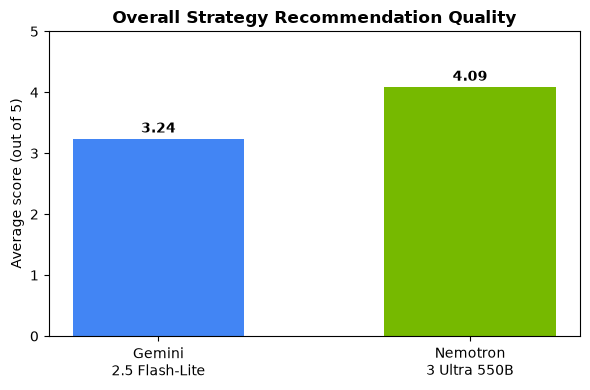

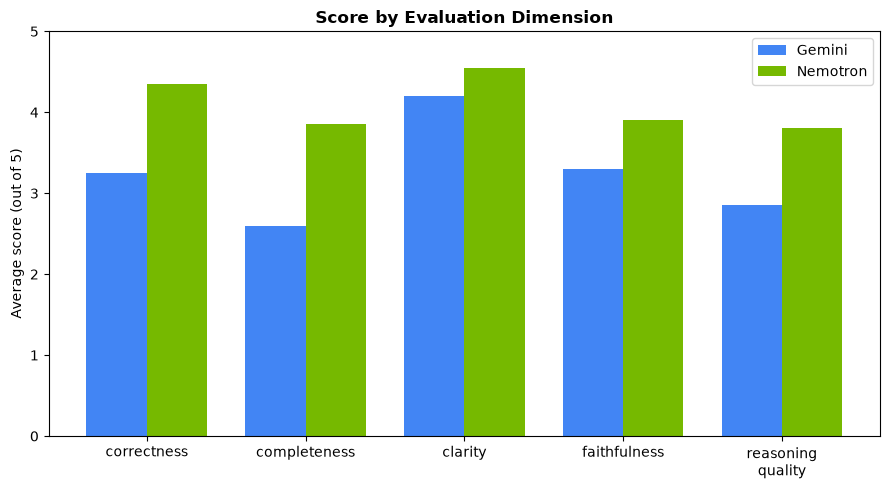

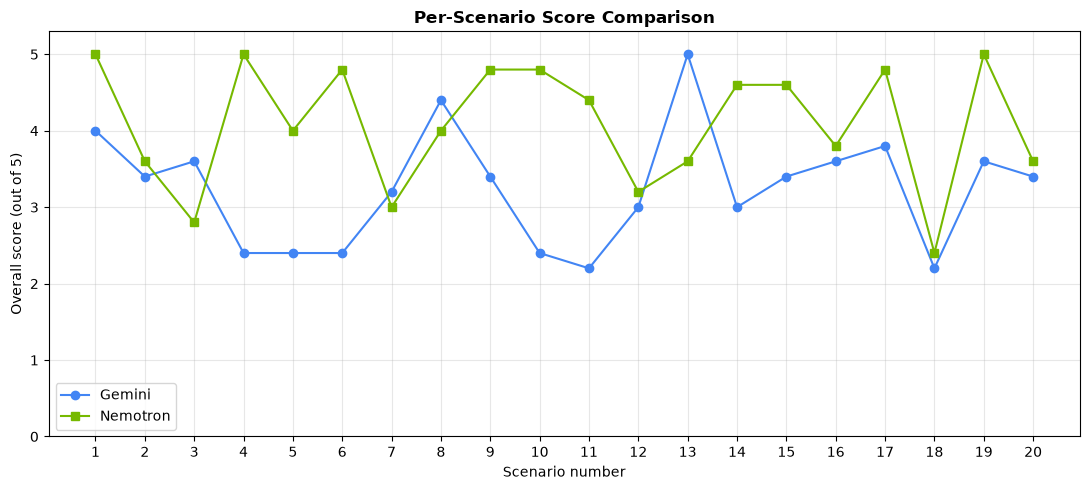

Saved 3 charts to results/ ✅


In [10]:

# Visualisation of the evaluation findings

import matplotlib.pyplot as plt
import numpy as np

BASE = os.path.expanduser('~/easyf1')
results_dir = os.path.join(BASE, 'results')
df = pd.read_csv(os.path.join(results_dir, 'scores_tidy.csv'))

dims = ['correctness', 'completeness', 'clarity', 'faithfulness', 'reasoning_quality']
dim_avg = df.groupby('model')[dims].mean()

GEM_COLOR = '#4285F4'   # Google blue
NEM_COLOR = '#76B900'   # NVIDIA green

# ---- Chart 1: Overall average ----
fig, ax = plt.subplots(figsize=(6, 4))
overall = df.groupby('model')['overall'].mean()
bars = ax.bar(['Gemini\n2.5 Flash-Lite', 'Nemotron\n3 Ultra 550B'],
              [overall['gemini'], overall['nemotron']],
              color=[GEM_COLOR, NEM_COLOR], width=0.55)
ax.set_ylabel('Average score (out of 5)')
ax.set_title('Overall Strategy Recommendation Quality', fontweight='bold')
ax.set_ylim(0, 5)
for bar, val in zip(bars, [overall['gemini'], overall['nemotron']]):
    ax.text(bar.get_x() + bar.get_width()/2, val + 0.1, f'{val:.2f}',
            ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'chart_overall.png'), dpi=150)
plt.show()

# ---- Chart 2: Per-dimension grouped bars ----
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(dims))
w = 0.38
ax.bar(x - w/2, dim_avg.loc['gemini', dims], w, label='Gemini', color=GEM_COLOR)
ax.bar(x + w/2, dim_avg.loc['nemotron', dims], w, label='Nemotron', color=NEM_COLOR)
ax.set_xticks(x)
ax.set_xticklabels([d.replace('_', '\n') for d in dims])
ax.set_ylabel('Average score (out of 5)')
ax.set_title('Score by Evaluation Dimension', fontweight='bold')
ax.set_ylim(0, 5)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'chart_dimensions.png'), dpi=150)
plt.show()

# ---- Chart 3: Per-scenario overall (shows spread) ----
fig, ax = plt.subplots(figsize=(11, 5))
gem = df[df['model']=='gemini'].sort_values('scenario_num')
nem = df[df['model']=='nemotron'].sort_values('scenario_num')
x = gem['scenario_num']
ax.plot(x, gem['overall'], 'o-', color=GEM_COLOR, label='Gemini', markersize=6)
ax.plot(x, nem['overall'], 's-', color=NEM_COLOR, label='Nemotron', markersize=6)
ax.set_xlabel('Scenario number')
ax.set_ylabel('Overall score (out of 5)')
ax.set_title('Per-Scenario Score Comparison', fontweight='bold')
ax.set_xticks(x)
ax.set_ylim(0, 5.3)
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(results_dir, 'chart_per_scenario.png'), dpi=150)
plt.show()

print("Saved 3 charts to results/ ✅")